# Travail Pratique 3

<div class="alert alert-block alert-success">
<b>Informations générales </b>
</div>

**Professeur**: Stephan Robert

**Assistant(s)**: Léonard Truscello

**Contact**: stephan.o.robert@gmail.com, leonard.truscello@heig-vd.ch ou via Teams

**Rendu**:

- Date: 5 novembre 2026 à 22h00
- Modalité: Travail individuel. Une fois complétées, copiez les réponses dans le ficher  "**TP3_APV_S1-2026_Nom_Prenom.ipynb" en remplaçant Nom et Prenom par les votres puis uploader votre fichier sur Cyberlearn.
- Note: Ce TP est noté sur 6, pour un poids de x%  

**Étudiant**:

- Mouhamed Sakho

**Remarques**:  

- Les résultats à obtenir sont présentés dans le notebook. Utilisez deux exemplaires du fichier pour comparer votre réponse et celle attendue   

- Assurez vous que le notebook se compile entièrement et sans erreur. Si ce n'est pas le cas, ajoutez un bloc pour commentez l'erreur et sa source potentielle. 

<div class="alert alert-block alert-success">

<b>But du TP </b>
</div>

- Le but de ce travail pratique est de retrouver la fonction de densité $f_{\theta}$ qui a générée un échantillon de points. Pour l'exercice 1, on va travailler avec des données discrètes et dans l'exercice 2, avec des données continues.
- Pour déterminer $f_{\theta}$, on va procéder de la manière suivante. Pour commencer, on va choisir plusieurs lois fonctions de densité candidats $f^{1}_{\theta_{1}}, \ldots f^{k}_{\theta_{k}}$.  Ensuite, on va utiliser mle pour estimer les paramètres $\theta_{1}, \ldots \theta_{k}$. Finalement, on va faire un plot de ces fonctions de densités ainsi que de la densité empirique. Finalement, en se basant sur ce graphe, on va essayer de retrouver la fonction de densité qui a générée cet échantillon.


<!---
<div class="alert alert-block alert-info">
<b>Rappel </b>
</div>
-->

<div class="alert alert-block alert-success">
<b>Table des matières </b>
</div>

Exercice 1
>* Visualisation des données
>* Estimation des paramètres
>* Représentation des distribution calculées.
>* Estimation de la distribution


Exercice 2
>* Visualisation des données
>* Estimation des paramètres
>* Représentation des distribution calculées.
>* Estimation de la distribution

## Exercice 1

Commençons par importer quelques packages.

In [1]:
import math
import numpy as np
import pickle
import matplotlib.pyplot as plt

Comme mentionné ci-dessus, la loi qui a générée les points présents dans le fichier 'data_ex1.pkl' est discrète.

### 1.1 Visualisation des données

Pour commencer, on va tracer la fonction de densité empirique utilisant notre échantillon.

In [2]:
file = open("data_ex1.pkl", "rb")
data = pickle.load(file)

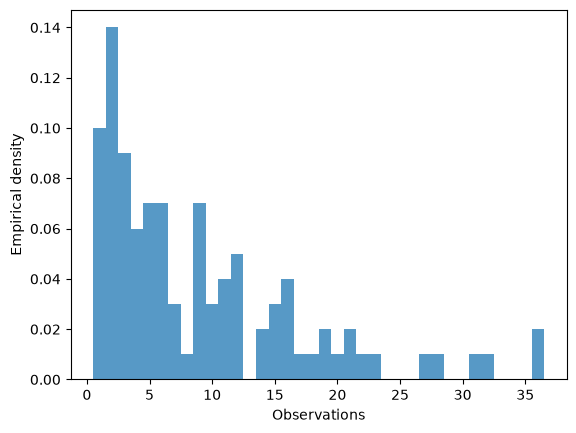

In [3]:
# TODO : faire le plot de la fonction de densité empirique
bins_ex1 = np.arange(data.min(), data.max() + 2) - 0.5   # une barre par entier
plt.hist(data, bins=bins_ex1, density=True, alpha=0.75)
plt.xlabel("Observations")
plt.ylabel("Empirical density")
plt.show()

### 1.2 Estimation des paramètres

On va maintenant implémenter plusieurs fonctions de densités et calculer les mle des paramètres de ces fonctions de densité.

In [4]:
"""
Un exemple pour la loi de Poisson
"""

# mle_estimation
def poisson_mle(data):
    return np.mean(data)

# poisson density function
def poisson_distribution(k, lmb):
    tmp = (lmb ** k) / math.factorial(k)
    return tmp * np.exp(-lmb)


Procéder de la même manière pour au moins $3$ fonctions de densités différentes.

In [5]:
# TODO : implement density functions and mle estimators for at least 3 different laws.

# --- Loi géométrique sur {1, 2, ...} : P(X=k) = p (1-p)^(k-1)
# L(p) = p^n (1-p)^(sum(x)-n)  =>  p_hat = n / sum(x) = 1 / mean(x)
def geometric_mle(data):
    return 1 / np.mean(data)

def geometric_distribution(k, p):
    return p * (1 - p) ** (k - 1)


# --- Loi binomiale B(n, p) avec n fixé (n = max observé) : P(X=k) = C(n,k) p^k (1-p)^(n-k)
# p_hat = mean(x) / n
def binomial_mle(data):
    n = int(np.max(data))
    return n, np.mean(data) / n

def binomial_distribution(k, n, p):
    return math.comb(n, k) * p ** k * (1 - p) ** (n - k)


# --- Loi uniforme discrète sur {a, ..., b} : P(X=k) = 1 / (b - a + 1)
# la vraisemblance est maximale pour l'intervalle le plus petit contenant les données
def uniform_mle(data):
    return int(np.min(data)), int(np.max(data))

def uniform_distribution(k, a, b):
    return 1 / (b - a + 1) if a <= k <= b else 0.0


lmb_hat = poisson_mle(data)
p_geo_hat = geometric_mle(data)
n_bin, p_bin_hat = binomial_mle(data)
a_hat, b_hat = uniform_mle(data)

print(f"Poisson    : lambda = {lmb_hat:.4f}")
print(f"Géométrique: p      = {p_geo_hat:.4f}")
print(f"Binomiale  : n = {n_bin}, p = {p_bin_hat:.4f}")
print(f"Uniforme   : a = {a_hat}, b = {b_hat}")

Poisson    : lambda = 8.9900
Géométrique: p      = 0.1112
Binomiale  : n = 36, p = 0.2497
Uniforme   : a = 1, b = 36


### 1.3 Représentation des distribution calculées.

En utilisant les paramètres calculés au point précédent, tracer les distributions $f^{1}_{\theta_{1}}, \ldots f^{k}_{\theta_{k}}$ ainsi que la densité empirique. Pour alléger le graphe, vous pouvez seulemement faire un plot des points. 

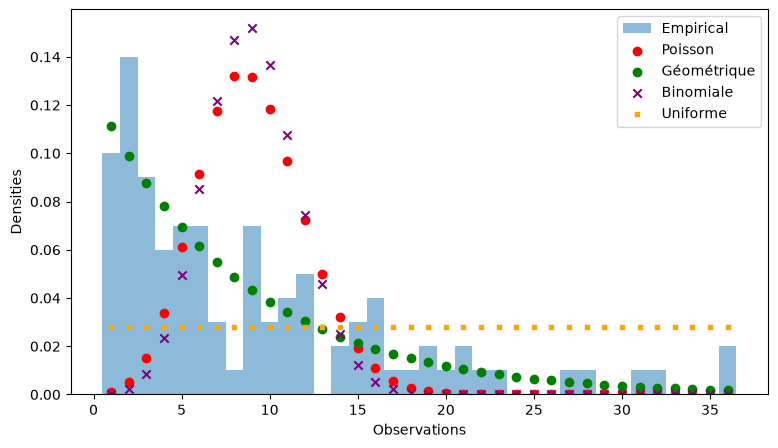

Poisson     : log L = -512.27
Géométrique : log L = -313.83
Binomiale   : log L = -658.54
Uniforme    : log L = -358.35


In [6]:
# TODO : plot the computed density functions and the empirical distribution
ks = np.arange(1, data.max() + 1)

plt.figure(figsize=(9, 5))
plt.hist(data, bins=bins_ex1, density=True, alpha=0.5, label="Empirical")
plt.scatter(ks, [poisson_distribution(int(k), lmb_hat) for k in ks], c="red", label="Poisson")
plt.scatter(ks, [geometric_distribution(int(k), p_geo_hat) for k in ks], c="green", label="Géométrique")
plt.scatter(ks, [binomial_distribution(int(k), n_bin, p_bin_hat) for k in ks], c="purple", marker="x", label="Binomiale")
plt.scatter(ks, [uniform_distribution(int(k), a_hat, b_hat) for k in ks], c="orange", marker="s", s=12, label="Uniforme")
plt.xlabel("Observations")
plt.ylabel("Densities")
plt.legend()
plt.show()

# Comparaison quantitative : log-vraisemblance de chaque modèle
loglik = {
    "Poisson": np.sum([np.log(poisson_distribution(int(k), lmb_hat)) for k in data]),
    "Géométrique": np.sum([np.log(geometric_distribution(int(k), p_geo_hat)) for k in data]),
    "Binomiale": np.sum([np.log(binomial_distribution(int(k), n_bin, p_bin_hat)) for k in data]),
    "Uniforme": np.sum([np.log(uniform_distribution(int(k), a_hat, b_hat)) for k in data]),
}
for name, ll in loglik.items():
    print(f"{name:12s}: log L = {ll:.2f}")

### 1.4 Estimation de la distribution

Selon les résulats obtenus essayer de déterminer la loi qui a générée les données présentes dans 'data_ex1.pkl' ainsi que le $\theta$ estimé.

In [7]:
# TODO: answer this question.
print(f"Loi retenue : géométrique (sur 1, 2, ...) avec p_hat = {p_geo_hat:.4f} (~ 1/9)")
print(f"Moyenne empirique = {np.mean(data):.2f}  vs  1/p = {1 / p_geo_hat:.2f}")
print(f"Variance empirique = {np.var(data):.2f}  vs  (1-p)/p^2 = {(1 - p_geo_hat) / p_geo_hat ** 2:.2f}")

Loi retenue : géométrique (sur 1, 2, ...) avec p_hat = 0.1112 (~ 1/9)
Moyenne empirique = 8.99  vs  1/p = 8.99
Variance empirique = 66.81  vs  (1-p)/p^2 = 71.83


**Réponse :** la densité empirique est maximale pour les petites valeurs (1-3) puis décroît
de manière quasi exponentielle avec une longue queue jusqu'à ~36. Poisson et binomiale sont
centrées autour de la moyenne (~9) et beaucoup trop étroites (variance ≈ 9 alors que la variance
empirique ≈ 67), l'uniforme est plate. Seule la **loi géométrique** suit la forme décroissante
et a aussi la plus grande log-vraisemblance. Les données ont donc été générées par une
loi géométrique de paramètre $\hat{p} = 1/\bar{x} \approx 0.111$ (≈ 1/9).

## Exercice 2

Essayer de retrouver la distribution qui a générée les points présents dans le file ci-joint. Mais contrairement à l'exercice précédent, on travaille maintenant avec une distribution continue.

In [8]:
file = open("data_ex2.pkl", "rb")
data = pickle.load(file)

### 2.1 Visualisation des données

Comme d'habitude, on commence par faire le plot des données. Comme on travaille maintenant avec des données continues, il pourrait être pertinent d'utiliser des histogrammes plus petits,  (par exemple $ \sim 0.1$).

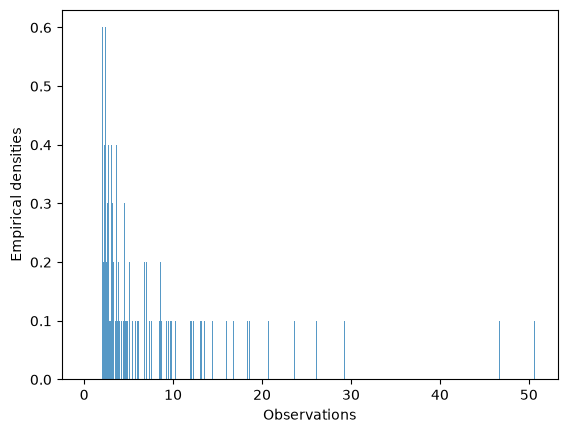

In [9]:
# TODO : plot the empirical densities
bins_ex2 = np.arange(0, data.max() + 0.1, 0.1)
plt.hist(data, bins=bins_ex2, density=True, alpha=0.75)
plt.xlabel("Observations")
plt.ylabel("Empirical densities")
plt.show()

### 2.2 Estimation des paramètres

Répéter la même procédure qu'à l'exercice $1.2$. Comme avant, on attend que vous tester au moins $3$ distributions différentes.

In [10]:
# TODO implement some continuous density functions and their mle estimators

# --- Loi normale N(mu, sigma^2) : mu_hat = mean, sigma_hat^2 = moyenne des (x - mu_hat)^2
def normal_mle(data):
    return np.mean(data), np.std(data)

def normal_density(x, mu, sigma):
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))


# --- Loi exponentielle : f(x) = lambda exp(-lambda x), lambda_hat = 1 / mean
def exponential_mle(data):
    return 1 / np.mean(data)

def exponential_density(x, lmb):
    return np.where(x >= 0, lmb * np.exp(-lmb * x), 0.0)


# --- Loi log-normale : ln(X) ~ N(mu, sigma^2), mle = moyenne / écart-type de ln(x)
def lognormal_mle(data):
    return np.mean(np.log(data)), np.std(np.log(data))

def lognormal_density(x, mu, sigma):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    pos = x > 0
    out[pos] = np.exp(-(np.log(x[pos]) - mu) ** 2 / (2 * sigma ** 2)) / (x[pos] * sigma * np.sqrt(2 * np.pi))
    return out


# --- Loi de Pareto : f(x) = alpha x_m^alpha / x^(alpha+1) pour x >= x_m
# x_m_hat = min(x), alpha_hat = n / sum(ln(x / x_m_hat))
def pareto_mle(data):
    xm = np.min(data)
    return xm, len(data) / np.sum(np.log(data / xm))

def pareto_density(x, xm, alpha):
    x = np.asarray(x, dtype=float)
    return np.where(x >= xm, alpha * xm ** alpha / np.maximum(x, xm) ** (alpha + 1), 0.0)


mu_n, sigma_n = normal_mle(data)
lmb_e = exponential_mle(data)
mu_ln, sigma_ln = lognormal_mle(data)
xm_p, alpha_p = pareto_mle(data)

print(f"Normale     : mu = {mu_n:.4f}, sigma = {sigma_n:.4f}")
print(f"Exponentielle: lambda = {lmb_e:.4f}")
print(f"Log-normale : mu = {mu_ln:.4f}, sigma = {sigma_ln:.4f}")
print(f"Pareto      : x_m = {xm_p:.4f}, alpha = {alpha_p:.4f}")

Normale     : mu = 7.1404, sigma = 8.0821
Exponentielle: lambda = 0.1400
Log-normale : mu = 1.6090, sigma = 0.7633
Pareto      : x_m = 2.0093, alpha = 1.0975


### 2.3 Représentation des distribution calculées.

En utilisant les paramètres calculés au point précédent, tracer les distributions $f^{1}_{\theta_{1}}, \ldots f^{k}_{\theta_{k}}$.

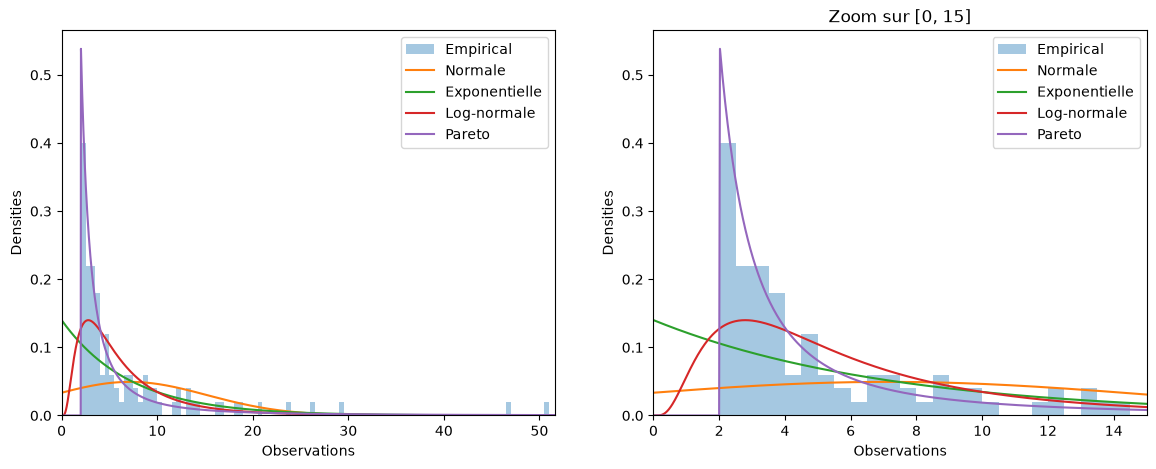

Normale      : log L = -350.86
Exponentielle: log L = -296.58
Log-normale  : log L = -275.78
Pareto       : log L = -251.59


In [11]:
# TODO : plot the computed density functions and the empirical density
xs = np.linspace(0.01, data.max() + 1, 2000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, xlim in zip(axes, [(0, data.max() + 1), (0, 15)]):
    ax.hist(data, bins=np.arange(0, data.max() + 0.5, 0.5), density=True, alpha=0.4, label="Empirical")
    ax.plot(xs, normal_density(xs, mu_n, sigma_n), label="Normale")
    ax.plot(xs, exponential_density(xs, lmb_e), label="Exponentielle")
    ax.plot(xs, lognormal_density(xs, mu_ln, sigma_ln), label="Log-normale")
    ax.plot(xs, pareto_density(xs, xm_p, alpha_p), label="Pareto")
    ax.set_xlim(*xlim)
    ax.set_xlabel("Observations")
    ax.set_ylabel("Densities")
    ax.legend()
axes[1].set_title("Zoom sur [0, 15]")
plt.show()

loglik2 = {
    "Normale": np.sum(np.log(normal_density(data, mu_n, sigma_n))),
    "Exponentielle": np.sum(np.log(exponential_density(data, lmb_e))),
    "Log-normale": np.sum(np.log(lognormal_density(data, mu_ln, sigma_ln))),
    "Pareto": np.sum(np.log(pareto_density(data, xm_p, alpha_p))),
}
for name, ll in loglik2.items():
    print(f"{name:13s}: log L = {ll:.2f}")

### 2.4 Estimation de la fonction de densité

Selon les résulats obtenus essayer de déterminer la distribution qui a générée les données présentes dans 'data_ex2.pkl' ainsi que le $\theta$ estimé.

In [12]:
# TODO : answer this question.
print(f"Loi retenue : Pareto avec x_m = {xm_p:.3f} (~2) et alpha = {alpha_p:.3f} (~1)")

Loi retenue : Pareto avec x_m = 2.009 (~2) et alpha = 1.098 (~1)


**Réponse :** aucune observation n'est inférieure à ~2, la densité est maximale juste après 2
puis décroît lentement avec des valeurs extrêmes (26, 50) : c'est une distribution à **queue lourde**
bornée à gauche. La normale (symétrique, donne des valeurs négatives) et l'exponentielle
(commence à 0 et décroît trop vite) ne collent pas. La log-normale est meilleure mais met de
la masse sous 2. La **loi de Pareto** reproduit le seuil et la queue et a la plus grande
log-vraisemblance : $\hat{x}_m = \min(x) \approx 2.01$ et $\hat{\alpha} \approx 1.10$
(vraisemblablement générée avec $x_m = 2$, $\alpha = 1$).

## Exercice 3


Dans cet exercice, nous allons nous intéresser à l'ouverture de **boosters de cartes à collectionner**, spécifiquement les cartes pokémons.

Un booster est un paquet contenant plusieurs cartes dont le contenu est inconnu avant son ouverture. Certaines cartes sont communes, tandis que d'autres sont beaucoup plus rares.

Nous allons étudier 6 catégories de cartes sorties dans la collection de l'anniversaire des 30 ans de pokémon: **EX, AR, Reprint, AR, Futuriste rare et RGB**. Chacune possède une probabilité d'apparition différente.

Pour chaque catégorie, nous disposons d'une séquence d'ouvertures de 99 boosters; ouvertures faites par l'assistant qui y a sacrifié une bonne partie de son salaire. Chaque ouverture est représentée par :
- `1` : au moins une carte de la catégorie recherchée a été obtenue.
- `0` : aucune carte de cette catégorie n'a été obtenue.

Nous supposons que les ouvertures sont indépendantes et que la probabilité d'obtenir une carte d'une catégorie donnée reste constante.

L'objectif est d'estimer ces probabilités à partir des observations, puis de les étudier à l'aide de la loi binomiale.

<div class="alert alert-block alert-success">

<b> Remarque </b>
</div>

- Pour l'exercice 3, vous êtes libre d'importer d'autres packages et de créer des blocs

In [13]:
# TODO : importer ici les packages nécessaires à l'exercice 3 qui ne sont pas déjà présent (si nécessaire).
import time
from IPython.display import display

In [14]:

# Voici les séquences obtenues (99 boosters chacune)

seq_ex = [
    1, 0, 0, 0, 0, 0, 0, 0, 1, 0,  # 1-10
    0, 0, 1, 0, 0, 0, 0, 0, 1, 0,  # 11-20
    0, 0, 0, 0, 0, 0, 0, 0, 1, 0,  # 21-30
    0, 0, 1, 0, 0, 1, 0, 0, 1, 0,  # 31-40
    0, 0, 0, 1, 0, 0, 0, 0, 0, 1,  # 41-50
    0, 0, 0, 1, 0, 0, 0, 0, 0, 0,  # 51-60
    0, 1, 0, 0, 0, 1, 0, 0, 0, 1,  # 61-70
    0, 0, 0, 0, 0, 1, 0, 0, 0, 0,  # 71-80
    0, 1, 0, 0, 0, 1, 0, 0, 0, 0,  # 81-90
    0, 1, 0, 0, 0, 0, 0, 0, 1     # 91-99
]

seq_ar = [
    0, 0, 1, 0, 1, 0, 0, 0, 0, 0,  # 1-10
    1, 0, 0, 0, 1, 1, 1, 1, 0, 0,  # 11-20
    1, 0, 0, 0, 1, 0, 0, 0, 0, 0,  # 21-30
    1, 0, 0, 1, 0, 0, 0, 1, 0, 1,  # 31-40
    0, 0, 1, 0, 0, 0, 0, 1, 0, 0,  # 41-50
    0, 1, 0, 0, 0, 1, 0, 0, 0, 0,  # 51-60
    0, 0, 0, 1, 0, 0, 0, 1, 0, 0,  # 61-70
    0, 1, 0, 0, 0, 0, 0, 0, 0, 1,  # 71-80
    0, 0, 0, 0, 0, 0, 1, 0, 0, 0,  # 81-90
    0, 0, 0, 0, 0, 0, 1, 0, 0     # 91-99
]

seq_reprint = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 1-10
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 11-20
    0, 0, 0, 1, 0, 0, 0, 0, 0, 0,  # 21-30
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 31-40
    0, 1, 0, 0, 0, 0, 0, 0, 0, 0,  # 41-50
    0, 0, 0, 0, 0, 0, 1, 0, 0, 0,  # 51-60
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 61-70
    0, 0, 0, 1, 0, 0, 0, 0, 0, 0,  # 71-80
    0, 0, 0, 0, 0, 0, 0, 0, 0, 1,  # 81-90
    0, 0, 0, 0, 0, 0, 0, 0, 0     # 91-99
]

seq_sar = [
    0, 0, 0, 0, 0, 0, 1, 0, 0, 0,  # 1-10
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 11-20
    0, 0, 1, 0, 0, 1, 1, 1, 0, 0,  # 21-30
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 31-40
    0, 0, 0, 0, 0, 1, 0, 0, 0, 0,  # 41-50
    0, 0, 0, 0, 0, 0, 0, 0, 1, 0,  # 51-60
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 61-70
    0, 0, 0, 0, 0, 0, 1, 0, 0, 0,  # 71-80
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 81-90
    0, 0, 0, 1, 0, 0, 0, 0, 0     # 91-99
]

seq_futuristic = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 1-10
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 11-20
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 21-30
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 31-40
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 41-50
    0, 0, 0, 0, 0, 0, 0, 0, 0, 1,  # 51-60
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 61-70
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 71-80
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 81-90
    0, 0, 0, 0, 0, 0, 0, 0, 0     # 91-99
]

seq_rgb = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 1-10
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 11-20
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 21-30
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 31-40
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 41-50
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 51-60
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 61-70
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 71-80
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0,  # 81-90
    0, 0, 0, 0, 0, 0, 0, 0, 0     # 91-99
]


In [15]:

# Nombre de cartes obtenues par catégorie de carte. 

print("EX :", sum(seq_ex))
print("AR :", sum(seq_ar))
print("Reprint :", sum(seq_reprint))
print("SAR :", sum(seq_sar))
print("Futuriste :", sum(seq_futuristic))
print("RGB :", sum(seq_rgb))

EX : 19
AR : 23
Reprint : 5
SAR : 9
Futuriste : 1
RGB : 0



### 3.1 Évolution de la fonction de vraisemblance

Pour une séquence de $n$ tirages contenant $k$ succès, la fonction de vraisemblance est définie par :

$$
L(p)=p^k(1-p)^{n-k}
$$

où $p \in [0,1]$ représente la probabilité d'obtenir un succès lors d'un tirage.

**Exemple :**

Considérons les cinq premiers tirages de la catégorie AR :

`[0, 0, 1, 0, 1]`

On note $p_{AR}$ la probabilité d'obtenir une carte AR lors d'un tirage.

Après chaque nouveau tirage, la fonction de vraisemblance est actualisée :
- Tirage 1 : $L(0 \mid p_{AR}) = (1-p_{AR})$
- Tirage 2 : $L(0,0 \mid p_{AR}) = (1-p_{AR})(1-p_{AR})$
- Tirage 3 : $L(0,0,1 \mid p_{AR}) = (1-p_{AR})(1-p_{AR})p_{AR}$
- Tirage 4 : $L(0,0,1,0 \mid p_{AR}) = (1-p_{AR})(1-p_{AR})p_{AR}(1-p_{AR})$
- Tirage 5 : $L(0,0,1,0,1 \mid p_{AR}) = (1-p_{AR})(1-p_{AR})p_{AR}(1-p_{AR})p_{AR}$

Ainsi, la fonction de vraisemblance est actualisée après chaque nouveau tirage.

---

<div class="alert alert-block alert-success">

<b>**TODO**</b>
</div>


Pour chacune des **6 séquences** (EX, AR, Reprint, SAR, Futuriste et RGB), réaliser un **graphique dynamique** montrant l'évolution de la fonction de vraisemblance au fil des tirages.

Votre programme devra respecter les consignes suivantes :

1. Afficher la fonction de vraisemblance sur l'intervalle $p \in [0,1]$.
2. Actualiser le graphique automatiquement, à raison d'**un nouveau tirage par 0.1 seconde** (10 tirages par seconde).
3. Recalculer et représenter la fonction de vraisemblance après chaque nouveau tirage, en tenant compte de l'ensemble des tirages déjà effectués.
4. Afficher **en haut à droite du graphique le numéro du tirage actuel**.
5. Conserver un **axe des abscisses fixe entre 0 et 1**. En revanche, l'axe des ordonnées devra s'adapter automatiquement, puisque la valeur maximale de la vraisemblance évolue au fil des tirages.

Vous devez obtenir **6 graphiques dynamiques distincts**, un pour chaque catégorie de carte.


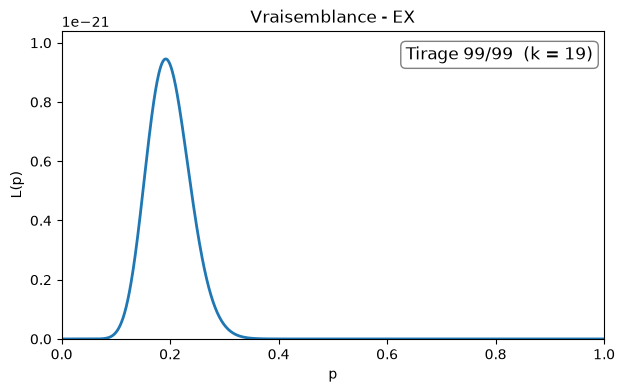

EX : k = 19, n = 99, p_hat (argmax) = 0.1920, k/n = 0.1919


In [16]:
# TODO
def likelihood(p, k, n):
    """L(p) = p^k (1-p)^(n-k) pour k succès sur n tirages."""
    return p ** k * (1 - p) ** (n - k)


def animate_likelihood(seq, name, delay=0.1):
    """Affiche l'évolution de la vraisemblance, un tirage toutes les `delay` secondes."""
    ps = np.linspace(0, 1, 1001)
    fig, ax = plt.subplots(figsize=(7, 4))
    line, = ax.plot([], [], lw=2)
    txt = ax.text(0.98, 0.95, "", transform=ax.transAxes, ha="right", va="top", fontsize=12,
                  bbox=dict(boxstyle="round", fc="white", ec="gray"))
    ax.set_xlim(0, 1)                     # axe des abscisses fixe
    ax.set_xlabel("p")
    ax.set_ylabel("L(p)")
    ax.set_title(f"Vraisemblance - {name}")
    handle = display(fig, display_id=True)
    plt.close(fig)

    k = 0
    for n, x in enumerate(seq, start=1):
        k += x
        L = likelihood(ps, k, n)
        line.set_data(ps, L)
        ax.set_ylim(0, L.max() * 1.1)     # axe des ordonnées adaptatif
        txt.set_text(f"Tirage {n}/{len(seq)}  (k = {k})")
        handle.update(fig)
        time.sleep(delay)

    p_hat = ps[np.argmax(L)]
    print(f"{name} : k = {k}, n = {len(seq)}, p_hat (argmax) = {p_hat:.4f}, k/n = {k / len(seq):.4f}")
    return p_hat


p_hats = {}
p_hats["EX"] = animate_likelihood(seq_ex, "EX")

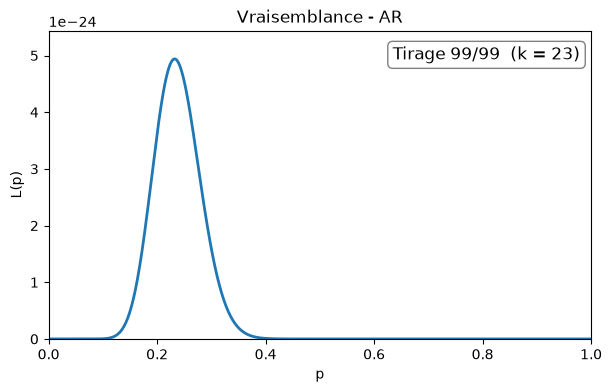

AR : k = 23, n = 99, p_hat (argmax) = 0.2320, k/n = 0.2323


In [17]:
p_hats["AR"] = animate_likelihood(seq_ar, "AR")

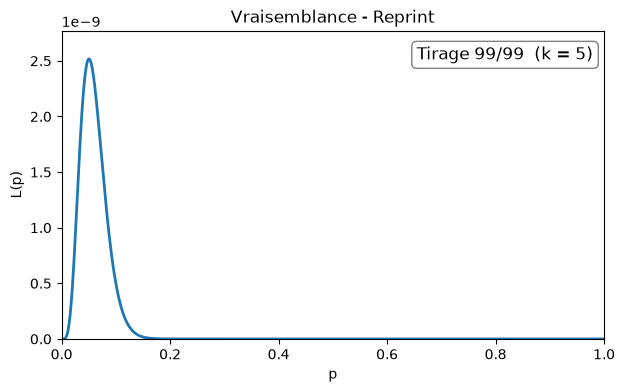

Reprint : k = 5, n = 99, p_hat (argmax) = 0.0510, k/n = 0.0505


In [18]:
p_hats["Reprint"] = animate_likelihood(seq_reprint, "Reprint")

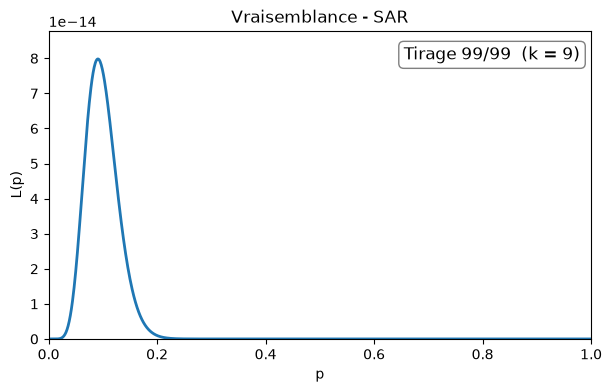

SAR : k = 9, n = 99, p_hat (argmax) = 0.0910, k/n = 0.0909


In [19]:
p_hats["SAR"] = animate_likelihood(seq_sar, "SAR")

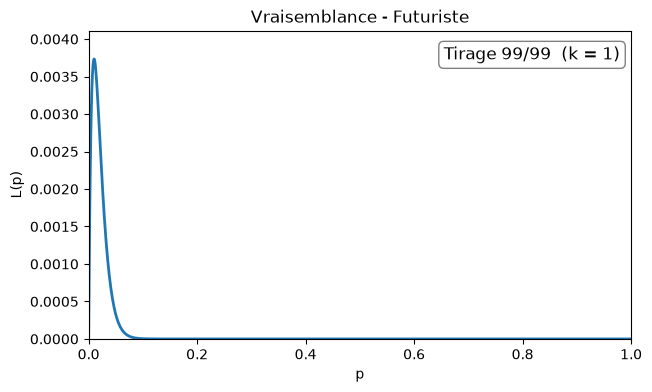

Futuriste : k = 1, n = 99, p_hat (argmax) = 0.0100, k/n = 0.0101


In [20]:
p_hats["Futuriste"] = animate_likelihood(seq_futuristic, "Futuriste")

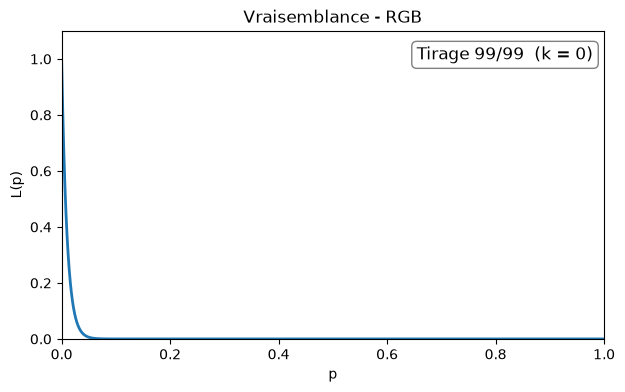

RGB : k = 0, n = 99, p_hat (argmax) = 0.0000, k/n = 0.0000


In [21]:
p_hats["RGB"] = animate_likelihood(seq_rgb, "RGB")

<div class="alert alert-block alert-success">

<b>TODO : Estimateur du maximum de vraisemblance</b>
</div>

L'**estimateur du maximum de vraisemblance**, noté $\hat{p}$, est la valeur de $p$ pour laquelle la fonction de vraisemblance atteint son maximum :

$$
\hat{p} = \arg\max_{p \in [0,1]} L(p)
$$

À partir des six graphiques obtenus après les 99 tirages, déterminez visuellement, pour chaque catégorie, la valeur de $\hat{p}$.

**Reportez vos six estimations :**

- $\hat{p}_{EX} = 19/99 \approx 0.192$
- $\hat{p}_{AR} = 23/99 \approx 0.232$
- $\hat{p}_{Reprint} = 5/99 \approx 0.051$
- $\hat{p}_{SAR} = 9/99 \approx 0.091$
- $\hat{p}_{Futuriste} = 1/99 \approx 0.010$
- $\hat{p}_{RGB} = 0$


(En annulant la dérivée de $\ln L(p) = k\ln p + (n-k)\ln(1-p)$ on retrouve $\hat{p} = k/n$, ce que confirment les graphiques.)

<div class="alert alert-block alert-success">

<b>Question</b>
</div>

Que pouvez-vous dire de l'évolution des graphiques ? Est-ce que certaines évolutions de la vraisemblance vous ont surprise ?   
   
   
Réponse :


- Au début, la courbe change beaucoup à chaque tirage : tant qu'aucune carte n'est sortie, $L(p)=(1-p)^n$ est maximale en $p=0$ ; dès le premier succès, $L(0)=0$ et le maximum saute vers $k/n$.
- Après chaque succès le pic se déplace vers la droite, après chaque échec il glisse lentement vers la gauche. Avec le nombre de tirages ces déplacements deviennent de plus en plus petits et le pic de plus en plus **étroit** : l'estimation se stabilise et devient plus précise (l'incertitude diminue en $\sim 1/\sqrt{n}$).
- La valeur maximale de $L$ diminue très vite (produit de 99 termes $<1$), d'où la nécessité d'un axe $y$ adaptatif ; seule la forme compte, pas la valeur absolue.
- Surprises : pour **RGB** la vraisemblance reste toujours $(1-p)^n$, collée à $p=0$ : on peut seulement dire que $p$ est petit, pas l'estimer. Pour **Futuriste** la courbe reste collée à 0 pendant 59 tirages puis « saute » au tirage 60. L'**AR** donne $\hat p \approx 0.23$, nettement au-dessus de la valeur théorique $1/6 \approx 0.167$, l'**EX** ($\approx 0.19$) est en dessous de $1/4$ et la **SAR** ($\approx 0.09$) vaut presque le double de $1/21 \approx 0.048$ : 99 boosters restent un petit échantillon.


### 3.2 Probabilité d'obtenir un nombre donné de cartes rares

Un assistant a ouvert **99 boosters** et a obtenu les cartes présentées ci-dessous.

Les probabilités théoriques d'obtenir chaque catégorie de carte sont estimées à :

| Rareté | Probabilité théorique $p$ | Nombre obtenu $k$ |
|---|---|---|
| EX | $1/4$ | 19 |
| AR | $1/6$ | 23 |
| Reprint | $1/10$ | 5 |
| SAR | $1/21$ | 9 |
| Futuriste | $1/120$ | 1 |
| RGB | $1/4096$ | 0 |

On rappelle que si $X$ représente le nombre de succès obtenus sur $N$ tirages indépendants, chacun ayant une probabilité $p$ de succès, alors $X$ suit une **loi binomiale** :

$$
X \sim \mathcal{B}(N,p)
$$

La probabilité d'obtenir exactement $k$ succès est donnée par :

$$
P(X=k)=\binom{N}{k}p^k(1-p)^{N-k}
$$

<div class="alert alert-block alert-success">

<b>TODO : Probabilités binomiales</b>
</div>

Pour chacune des six catégories, calculez la probabilité que l'assistant ait obtenu **exactement le nombre de cartes observé** lors de l'ouverture des 99 boosters.

Présentez vos résultats sous forme de pourcentages.


In [22]:
# TODO : implémenter la loi binomiale pour les boosters de cartes et calculer les probabilités demandées
def binomial_pmf(k, N, p):
    """P(X = k) pour X ~ B(N, p)."""
    return math.comb(N, k) * p ** k * (1 - p) ** (N - k)


N_boosters = 99
theory = {  # rareté: (p théorique, k obtenu)
    "EX": (1 / 4, sum(seq_ex)),
    "AR": (1 / 6, sum(seq_ar)),
    "Reprint": (1 / 10, sum(seq_reprint)),
    "SAR": (1 / 21, sum(seq_sar)),
    "Futuriste": (1 / 120, sum(seq_futuristic)),
    "RGB": (1 / 4096, sum(seq_rgb)),
}

print(f"{'Rareté':10s} {'p':>9s} {'k':>3s} {'E[X]=Np':>8s} {'P(X=k)':>9s}")
for name, (p, k) in theory.items():
    print(f"{name:10s} {p:9.5f} {k:3d} {N_boosters * p:8.2f} {100 * binomial_pmf(k, N_boosters, p):8.2f}%")

Rareté             p   k  E[X]=Np    P(X=k)
EX           0.25000  19    24.75     3.94%
AR           0.16667  23    16.50     2.33%
Reprint      0.10000   5     9.90     3.57%
SAR          0.04762   9     4.71     2.70%
Futuriste    0.00833   1     0.82    36.33%
RGB          0.00024   0     0.02    97.61%


**Commentaire :** aucune de ces probabilités n'est grande car, avec 99 tirages, beaucoup de valeurs
de $k$ sont possibles. EX (19 au lieu de ~25 attendues) et AR (23 au lieu de ~16.5) s'écartent un peu
de l'espérance ; SAR (9 au lieu de ~4.7) est le résultat le plus inhabituel. Futuriste (1 pour ~0.8
attendue) et surtout RGB (0, avec $P\approx 97.6\%$) sont tout à fait conformes à la théorie.


### 3.3 Interprétation de l'espérance et étude des probabilités

Nous avons vu que l'espérance d'une loi binomiale est donnée par :

$$
E[X]=Np
$$

Prenons l'exemple des cartes EX, dont la probabilité d'apparition est de $p=1/4$.

Si nous ouvrons 4 boosters, nous avons :

$$
E[X]=4\times\frac14=1
$$

Nous pouvons donc espérer obtenir **en moyenne une carte EX pour 4 boosters ouverts**.

Mais cela signifie-t-il que nous allons nécessairement obtenir une carte EX en ouvrant 4 boosters ?

Nous pouvons également n'en obtenir aucune, ou en obtenir plusieurs !

<div class="alert alert-block alert-success">

<b>TODO : Calcul des probabilités</b>
</div>

Pour chaque catégorie de rareté, nous considérons un nombre de boosters $N$ tel que l'espérance du nombre de cartes obtenues soit égale à 1.

À l'aide de la loi binomiale, calculez :

- $P(X=0)$ : la probabilité de n'obtenir aucune carte de cette rareté.
- $P(X=1)$ : la probabilité d'obtenir exactement une carte.
- $P(X\geq 2)$ : la probabilité d'obtenir deux cartes ou plus.

Complétez le tableau suivant :

| Rareté | Probabilité $p$ | Nombre de boosters $N$ | $P(X=0)$ | $P(X=1)$ | $P(X\geq 2)$ |
|---|---|---|---|---|---|
| EX | $1/4$ | 4 | | | |
| AR | $1/6$ | 6 | | | |
| Reprint | $1/10$ | 10 | | | |
| SAR | $1/21$ | 21 | | | |
| Futuriste | $1/120$ | 120 | | | |
| RGB | $1/4096$ | 4096 | | | |


In [23]:
# TODO : Calculez les valeurs en pourcentage arrondis avec 2 chiffres après la virgule et donnez le tableau.
rows = []
for name, (p, _) in theory.items():
    N = round(1 / p)
    p0 = binomial_pmf(0, N, p)
    p1 = binomial_pmf(1, N, p)
    rows.append((name, f"1/{N}", N, round(100 * p0, 2), round(100 * p1, 2), round(100 * (1 - p0 - p1), 2)))

print(f"{'Rareté':10s} {'p':>7s} {'N':>5s} {'P(X=0)':>8s} {'P(X=1)':>8s} {'P(X>=2)':>8s}")
for name, p_str, N, p0, p1, p2 in rows:
    print(f"{name:10s} {p_str:>7s} {N:5d} {p0:7.2f}% {p1:7.2f}% {p2:7.2f}%")

Rareté           p     N   P(X=0)   P(X=1)  P(X>=2)
EX             1/4     4   31.64%   42.19%   26.17%
AR             1/6     6   33.49%   40.19%   26.32%
Reprint       1/10    10   34.87%   38.74%   26.39%
SAR           1/21    21   35.89%   37.69%   26.42%
Futuriste    1/120   120   36.63%   36.94%   26.42%
RGB         1/4096  4096   36.78%   36.79%   26.42%



<div class="alert alert-block alert-success">

<b>TODO : Représentation graphique</b>
</div>

Nous allons maintenant étudier ce qui se passe lorsque le nombre de boosters $N$ augmente, en conservant toujours une espérance égale à 1 :

$$
p=\frac1N
$$

Réalisez **un seul graphique contenant les six courbes** suivantes :

- $P(X=0)$
- $P(X=1)$
- $P(X=2)$
- $P(X=3)$
- $P(X=4)$
- $P(X\geq 5)$

L'axe des abscisses représente le nombre de boosters $N$ et l'axe des ordonnées représente les probabilités.

Faites varier N sur plusieurs ordres de grandeur (jusqu'à minimum $10^6$). Utilisez une couleur différente pour chaque courbe et ajoutez une légende.


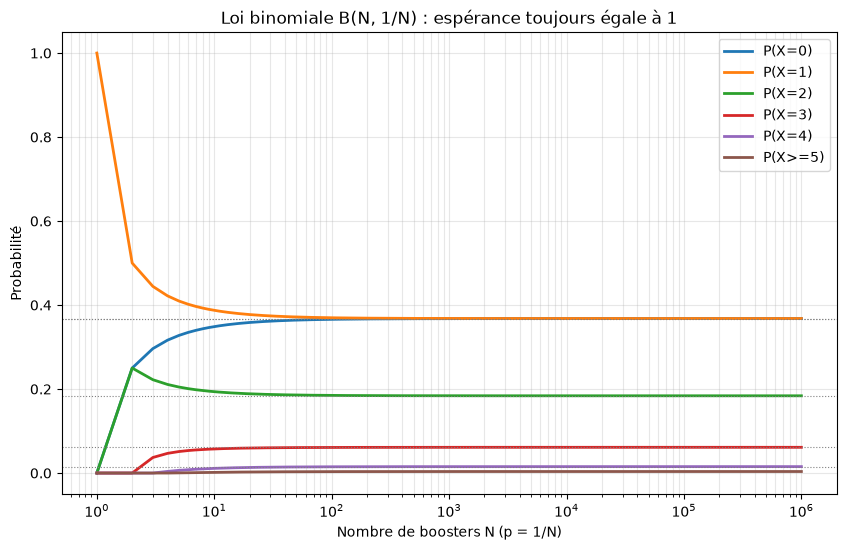

N = 1e6           : {'P(X=0)': np.float64(36.79), 'P(X=1)': np.float64(36.79), 'P(X=2)': np.float64(18.39), 'P(X=3)': np.float64(6.13), 'P(X=4)': np.float64(1.53), 'P(X>=5)': np.float64(0.37)}
Limite Poisson(1) : {'P(X=0)': np.float64(36.79), 'P(X=1)': np.float64(36.79), 'P(X=2)': np.float64(18.39), 'P(X=3)': np.float64(6.13), 'P(X=4)': np.float64(1.53)} P(X>=5) = 0.37


In [24]:
Ns = np.unique(np.logspace(0, 6, 400).astype(int))
curves = {f"P(X={k})": [] for k in range(5)}
curves["P(X>=5)"] = []
for N in Ns:
    p = 1 / N
    probs = [binomial_pmf(k, int(N), p) if k <= N else 0.0 for k in range(5)]
    for k in range(5):
        curves[f"P(X={k})"].append(probs[k])
    curves["P(X>=5)"].append(max(0.0, 1 - sum(probs)))

plt.figure(figsize=(10, 6))
for label, values in curves.items():
    plt.plot(Ns, values, label=label, lw=2)
for k in range(5):  # limites de Poisson(1)
    plt.axhline(np.exp(-1) / math.factorial(k), color="gray", ls=":", lw=0.8)
plt.xscale("log")
plt.xlabel("Nombre de boosters N (p = 1/N)")
plt.ylabel("Probabilité")
plt.title("Loi binomiale B(N, 1/N) : espérance toujours égale à 1")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

print("N = 1e6           :", {k: round(100 * v[-1], 2) for k, v in curves.items()})
print("Limite Poisson(1) :", {f"P(X={k})": round(100 * np.exp(-1) / math.factorial(k), 2) for k in range(5)},
      "P(X>=5) =", round(100 * (1 - sum(np.exp(-1) / math.factorial(k) for k in range(5))), 2))


<div class="alert alert-block alert-success">

<b>**Questions :**</b>
</div>


1. Comment évoluent ces six probabilités lorsque $N$ augmente ?
2. Vers quelles valeurs semblent-elles converger ?
3. Que pouvez-vous conclure sur la signification concrète d'une espérance égale à 1 ?


**Réponses :**

1. Pour $N=1$ on a $p=1$ donc $P(X=1)=1$ et toutes les autres valent 0. Quand $N$ augmente, $P(X=1)$ chute rapidement, $P(X=0)$ monte (25% pour $N=2$, 29.6% pour $N=3$, ...), $P(X=2)$ passe par un maximum (25% pour $N=2$) puis redescend vers 18.4%, et $P(X=3)$, $P(X=4)$, $P(X\geq5)$ apparaissent dès que $N$ le permet puis augmentent légèrement. Les courbes varient fortement pour $N<100$ puis deviennent quasiment plates.
2. Elles convergent vers la **loi de Poisson de paramètre $\lambda = Np = 1$** : $P(X=k) \to e^{-1}/k!$, soit $P(X=0)=P(X=1)\approx 36.79\%$, $P(X=2)\approx 18.39\%$, $P(X=3)\approx 6.13\%$, $P(X=4)\approx 1.53\%$ et $P(X\geq5)\approx 0.37\%$.
3. Une espérance de 1 ne garantit **pas** d'obtenir une carte : pour une carte rare (grand $N$), on a environ **37% de chances de n'en avoir aucune** après avoir ouvert les $N$ boosters, autant d'en avoir exactement une, et ~26% d'en avoir plusieurs. L'espérance est une moyenne sur un grand nombre de répétitions, pas un résultat garanti pour une seule série d'ouvertures (pour la RGB : 4096 boosters ouverts et 36.8% de chances de repartir sans aucune).
